# 5.5 - From predictions to portfolios

> **Needs:** the out-of-sample signals of notebooks 5.3 and 5.4; the database.
>
> **Produces:** 44 registered runs of the family `ml4t_strategy_monthly`, their books and returns kept in the artifact store for notebooks 5.6 and 5.11.

Notebooks 5.3 and 5.4 judged the models by how well they *ranked* companies each month (the rank IC). An investor is
paid in returns, after costs. This notebook turns four out-of-sample signals into portfolios, every way the plan
prescribes, and measures them over 2015-2024, after trading costs:

* **Signals** (all out of sample, 2015-2024): the composite of issuance and ROCE; the logistic regression of 5.3 (the
  best linear model); and the two gradient-boosted runs of 5.4 (the grid tuned in each fold, and the Optuna-tuned
  settings).
* **Entry**: each month end, the top tenth of the S&P 1500 by signal - held alone (**long-only**), or held long while
  the bottom tenth is held short (**long-short**, as much short as long: a bet on the ranking alone, not the market).
* **Weighting within each side**: equal; inverse volatility; hierarchical risk parity; mean-variance on the risk
  model's covariance (definitions below).
* **Overlays** on the four long-only equal-weighted books: a volatility target, drawdown control, and half-Kelly
  scaling.

Every one of these 44 strategies is registered in the new family `ml4t_strategy_monthly`, so each deflated Sharpe
ratio counts all 44. Notebook 5.6 then assesses them: costs, tail risk, drift, the Fundamental Law and tests that
allow for having picked the best of many.

## Weighting and overlays

| Method | Each side's weights | Why |
|---|---|---|
| Equal | $1/n$ each | the simplest; no estimate can be wrong |
| Inverse volatility | $\propto 1/\sigma_i$, $\sigma_i$ the volatility of the last 63 days | each name adds about the same risk |
| Hierarchical risk parity (Lopez de Prado, 2016) | names clustered by the correlation of the past year's returns; capital split down the cluster tree in inverse proportion to each branch's variance | diversifies across groups that move together, without inverting a noisy covariance matrix |
| Mean-variance | $\propto \Sigma^{-1}\alpha$, negatives set to 0 | the classic optimum: $\Sigma$ from the risk model of notebook 4.2 (factor covariance plus specific variance), $\alpha_i = z_i\,\sigma_i$ (Grinold's rule: forecast = IC x volatility x score) |

| Overlay | Exposure each day (known the day before) |
|---|---|
| Volatility target | 15 % over the strategy's annualised volatility of the past 63 days, at most 1.5 |
| Drawdown control | 1, or 0.5 while the strategy is more than 15 % below its peak |
| Half Kelly | half of the mean over the variance of the past year's daily returns, between 0 and 1.5 |

A change of exposure is charged 10 basis points a unit. Trading costs are the universe's, by size segment, as in
every backtest of this repository; shorts also pay the universe's borrowing fee.

In [1]:
import pandas as pd
from IPython.display import display

from equity_research.analytics.indices import vendor_returns
from equity_research.analytics.risk import risk_model as rm
from equity_research.analytics.risk.risk_data import load_risk_inputs
from equity_research.analytics.risk.risk_styles import substyles
from equity_research.data import artifacts as store
from equity_research.data.cache import ResearchCache
from equity_research.data.universe import load_universe_data
from equity_research.ml import boosting as gb
from equity_research.ml import linear as ln
from equity_research.ml import ml_strategy as ms
from equity_research.ml.features import unstack
from equity_research.research.notebook import slug
from research_core import charts
from research_core.analytics.signals import labels as lb
from research_core.analytics.signals import validation as va
from research_core.data.db.engine import get_engine
from research_core.engine import allocation as al
from research_core.engine.finish import deflated_active
from research_core.engine.registry import record_search, trial_count

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
charts.style()

UNIVERSE, START, END = "SP1500", "2005-01-01", "2024-12-31"  # END: the last day before the hold-out
FIRST_TEST, LAST_TEST, TRAIN_YEARS, OPTUNA_TRIALS = 2015, 2024, 10, 40
cache = ResearchCache()
SNAPSHOT = store.data_snapshot(cache)
data = load_universe_data(cache, UNIVERSE, START, END)
dates = data.rebalances
test_dates = dates[(dates.year >= FIRST_TEST) & (dates.year <= LAST_TEST)]
FEATURES = {"universe": UNIVERSE, "start": START, "end": END, "dates": "month ends", "version": 1}
long = store.load("features", "company_month_end", FEATURES, snapshot=SNAPSHOT)
assert long is not None, "run notebooks 5.2-5.4 first"
monthly = store.cached(
    "labels",
    "fwd_ret_month",
    {"universe": UNIVERSE, "start": START, "end": END, "dates": "rebalances"},
    lambda: lb.period_returns(data.returns, dates),
    snapshot=SNAPSHOT,
)
x = ln.centred_ranks(long)
y = lb.trimmed_excess(monthly, data.members)
ends = va.next_date_ends(dates)
folds = va.walk_forward(dates, ends, train_years=TRAIN_YEARS, first_test=FIRST_TEST, last_test=LAST_TEST)
STUDY = FEATURES | {
    "target": "trimmed excess, 1 %",
    "train_years": TRAIN_YEARS,
    "first_test": FIRST_TEST,
    "flat": "ic 0",
}

left out 1078 facts of 2 companies in ['GBP']


## Step 1 - the four signals, read back from 5.3 and 5.4

In [2]:
panels = unstack(long)
logistic = ln.stored_walk_forward(
    x, y, folds, ends, ln.MODELS["logistic"], name="logistic", config=STUDY, snapshot=SNAPSHOT
)
grid_run = gb.stored_walk_forward(x, y, folds, ends, gb.grid(), name="grid", config=STUDY, snapshot=SNAPSHOT)
loss = gb.grid()[str(grid_run.tuning.loc[min(grid_run.tuning.index)].idxmax())].loss
_, best = gb.stored_search(
    x, y, folds[0].train, ends, loss=loss, n_trials=OPTUNA_TRIALS, config=STUDY, snapshot=SNAPSHOT
)
tuned_run = gb.stored_walk_forward(x, y, folds, ends, {"optuna": best}, name="optuna", config=STUDY, snapshot=SNAPSHOT)
signals = {
    "Composite": ln.composite({"issuance": -panels["share_change"], "ROCE": panels["ROCE"]}, data.members),
    "Logistic (6.3)": logistic.scores,
    "GBM grid (6.4)": grid_run.scores,
    "GBM Optuna (6.4)": tuned_run.scores,
}
signals = {name: s.reindex(index=test_dates, columns=data.returns.columns) for name, s in signals.items()}
print({name: f"{s.notna().sum(axis=1).median():.0f} names a month" for name, s in signals.items()})

{'Composite': '1500 names a month', 'Logistic (6.3)': '1504 names a month', 'GBM grid (6.4)': '1504 names a month', 'GBM Optuna (6.4)': '1504 names a month'}


## Step 2 - the risk model for mean-variance weights

Notebook 4.2's model of the S&P 1500 (BFRE 2.0: industries, styles, specific risk), with forecasts on the month ends
of the test years. Its covariance on a month end uses only returns up to that day.

In [3]:
inputs = load_risk_inputs(cache, data)
exposures = rm.style_exposures(substyles(inputs), inputs)
forecast_days = [d for d in test_dates if d in set(data.returns.index)]
model = rm.build_risk_model(data.returns, exposures, forecast_days)
print(f"risk model: forecasts on {len(model.dates)} month ends, {len(exposures.styles)} styles")

left out 1078 facts of 2 companies in ['GBP']


risk model: forecasts on 120 month ends, 12 styles


## Step 3 - 32 portfolios: four signals, two entries, four weightings

Each book is rebalanced at the month ends of 2015-2024 and backtested day by day to the end of 2024, after costs. The
books and their daily results are kept in the artifact store for notebook 5.6.

In [4]:
KEY = STUDY | {"strategies": "P4 v1"}

results, books, specs = {}, {}, {}
for signal, score in signals.items():
    for entry, long_only in (("long-only", True), ("long-short", False)):
        for method in al.METHODS:
            name = f"{signal} | {entry} | {method}"
            book = store.cached(
                "strategy",
                f"book-{slug(name)}",
                KEY,
                lambda s=score, m=method, lo=long_only: al.decile_book(
                    s, data.members, test_dates, data.returns, method=m, long_only=lo, risk=model.on
                ),
                snapshot=SNAPSHOT,
            )
            book.index = pd.DatetimeIndex(book.index)
            result = ms.backtest(book, data, END)
            store.save(
                pd.DataFrame(
                    {"gross": result.gross, "net": result.net, "turnover": result.turnover, "costs": result.costs}
                ),
                "strategy",
                f"daily-{slug(name)}",
                KEY,
                snapshot=SNAPSHOT,
            )
            results[name], books[name] = result, book
            specs[name] = {"signal": signal, "entry": entry, "method": method, "overlay": "none"}
print(f"{len(results)} portfolios backtested")

32 portfolios backtested


## Step 4 - overlays on the long-only, equally weighted books

In [5]:
OVERLAYS = {
    "vol target 15%": lambda n: al.vol_target(n, target=0.15),
    "drawdown control": lambda n: al.drawdown_control(n, threshold=0.15, cut=0.5),
    "half Kelly": lambda n: al.kelly(n, fraction=0.5),
}
nets = {name: r.net for name, r in results.items()}
for signal in signals:
    base = nets[f"{signal} | long-only | equal"]
    for overlay, rule in OVERLAYS.items():
        name = f"{signal} | long-only | equal | {overlay}"
        nets[name] = al.apply_exposure(base, rule(base), cost_bps=10)
        store.save(nets[name].to_frame(), "strategy", f"daily-{slug(name)}", KEY, snapshot=SNAPSHOT)
        specs[name] = {"signal": signal, "entry": "long-only", "method": "equal", "overlay": overlay}
print(f"{len(nets)} strategies in all")

44 strategies in all


## Step 5 - every strategy measured and registered

Long-only strategies against the index (the S&P 1500 fund, SPTM, the universe's benchmark); long-short strategies
against cash, so their "active" measures are their own return, volatility and Sharpe ratio. The deflated ratio counts
every strategy of the family: the probability that the information ratio (long-only) or Sharpe ratio (long-short)
beats what the luckiest of that many strategies would show by chance.

In [6]:
# the registry is the shared database: connected only now, as a serverless database pauses when idle
engine = get_engine()
rows = {
    name: ms.measure(net.loc[str(FIRST_TEST) :], data.benchmark, long_only=specs[name]["entry"] == "long-only")
    | {"turnover": float(results[name].metrics()["turnover"]) if name in results else float("nan")}
    for name, net in nets.items()
}
points = [
    (specs[name] | {"study": "5.5", "period": f"{FIRST_TEST}-{LAST_TEST}"}, metrics) for name, metrics in rows.items()
]
ids = record_search(engine, ms.FAMILY, points, asset_class="equity", stage="backtest", search="P4 strategies")
trials = trial_count(engine, ms.FAMILY)
table = pd.DataFrame(rows).T
table["deflated"] = [
    deflated_active(nets[n].loc[str(FIRST_TEST) :], data.benchmark, float(table.loc[n, "information_ratio"]), trials)
    if specs[n]["entry"] == "long-only"
    else ms.deflated_sharpe_of(nets[n].loc[str(FIRST_TEST) :], float(table.loc[n, "sharpe"]), trials)
    for n in table.index
]
store.save(table, "strategy", "summary", KEY, snapshot=SNAPSHOT)
COLUMNS = {
    "cagr": "{:.1%}",
    "vol": "{:.1%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.0%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated": "{:.0%}",
    "turnover": "{:.1f}",
}
for entry in ("long-only", "long-short"):
    part = table[[specs[n]["entry"] == entry for n in table.index]].sort_values("information_ratio", ascending=False)
    print(f"{entry} ({'against SPTM' if entry == 'long-only' else 'against cash'}), 2015-2024")
    display(part[list(COLUMNS)].style.format(COLUMNS, na_rep=""))
print(f"Registered runs {ids[0]}-{ids[-1]}; trials in the family: {trials}")

long-only (against SPTM), 2015-2024


,cagr,vol,sharpe,max_drawdown,active_return,tracking_error,information_ratio,deflated,turnover
Logistic (6.3) | long-only | mean_variance,14.8%,19.6%,0.80,-38%,+1.5%,7.3%,+0.29,9%,12.9
GBM grid (6.4) | long-only | mean_variance,14.9%,22.9%,0.72,-36%,+1.5%,12.4%,+0.20,5%,18.8
Composite | long-only | mean_variance,13.2%,20.4%,0.71,-41%,+0.1%,7.3%,+0.08,3%,4.5
GBM Optuna (6.4) | long-only | mean_variance,12.8%,22.8%,0.64,-35%,-0.3%,12.3%,+0.05,2%,18.8
Composite | long-only | equal,12.3%,20.9%,0.66,-43%,-0.8%,7.8%,-0.01,1%,3.1
Composite | long-only | inverse_vol,12.5%,19.4%,0.70,-41%,-0.6%,6.3%,-0.03,1%,3.6
GBM Optuna (6.4) | long-only | equal,10.1%,22.5%,0.54,-38%,-2.7%,10.9%,-0.17,0%,15.3
GBM grid (6.4) | long-only | equal,9.6%,22.7%,0.52,-38%,-3.2%,11.3%,-0.20,0%,15.4
GBM Optuna (6.4) | long-only | inverse_vol,10.2%,21.2%,0.56,-38%,-2.6%,9.8%,-0.21,0%,15.9
Composite | long-only | hrp,11.7%,17.5%,0.72,-38%,-1.2%,5.4%,-0.21,0%,4.9


long-short (against cash), 2015-2024


,cagr,vol,sharpe,max_drawdown,active_return,tracking_error,information_ratio,deflated,turnover
Composite | long-short | mean_variance,6.9%,11.2%,0.65,-24%,+6.9%,11.2%,+0.65,43%,9.5
Logistic (6.3) | long-short | mean_variance,7.8%,16.4%,0.54,-43%,+7.8%,16.4%,+0.54,30%,27.1
GBM grid (6.4) | long-short | mean_variance,8.3%,33.0%,0.42,-61%,+8.3%,33.0%,+0.42,19%,35.0
GBM Optuna (6.4) | long-short | mean_variance,5.9%,35.3%,0.35,-66%,+5.9%,35.3%,+0.35,14%,34.8
Composite | long-short | inverse_vol,2.5%,9.0%,0.32,-27%,+2.5%,9.0%,+0.32,11%,8.2
Composite | long-short | hrp,1.9%,8.5%,0.26,-29%,+1.9%,8.5%,+0.26,8%,11.0
Composite | long-short | equal,2.4%,11.7%,0.26,-32%,+2.4%,11.7%,+0.26,8%,7.4
GBM Optuna (6.4) | long-short | equal,1.1%,19.2%,0.15,-43%,+1.1%,19.2%,+0.15,4%,28.9
GBM Optuna (6.4) | long-short | inverse_vol,0.4%,15.0%,0.10,-41%,+0.4%,15.0%,+0.10,3%,31.1
GBM grid (6.4) | long-short | equal,-1.0%,18.9%,0.04,-51%,-1.0%,18.9%,+0.04,2%,28.9


Registered runs 117-160; trials in the family: 44


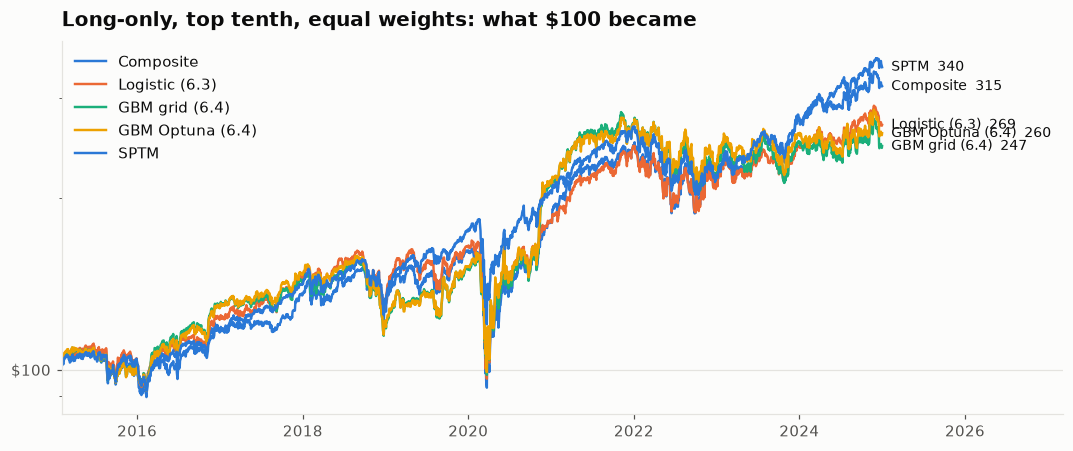

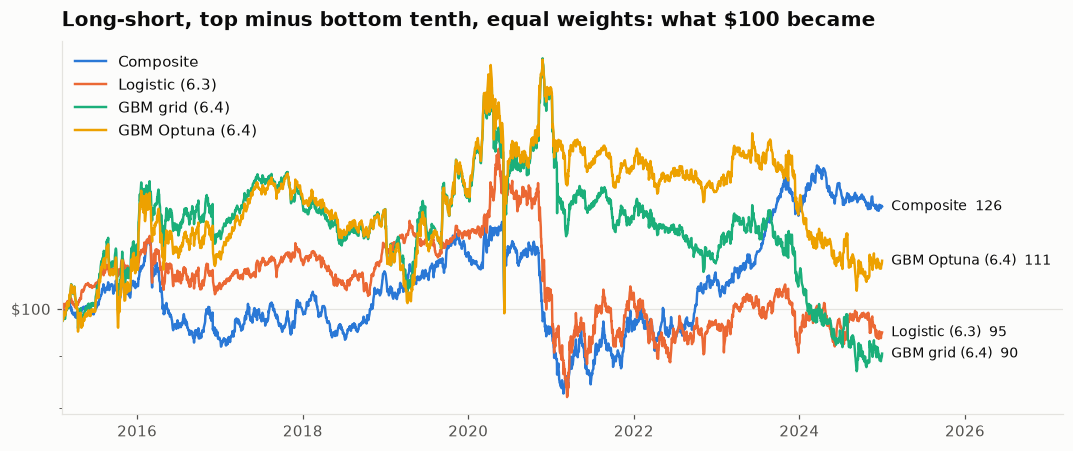

In [7]:
sptm = vendor_returns(cache, "SPTM", total=True).loc[str(FIRST_TEST) : END]
shown = {s: nets[f"{s} | long-only | equal"].loc[str(FIRST_TEST) :] for s in signals}
fig = charts.growth(shown | {"SPTM": sptm}, "Long-only, top tenth, equal weights: what $100 became")
shown = {s: nets[f"{s} | long-short | equal"].loc[str(FIRST_TEST) :] for s in signals}
fig = charts.growth(shown, "Long-short, top minus bottom tenth, equal weights: what $100 became")

## Findings

*Rerun on 17 November 2026 on quant_research_local (history from 2000). The conclusions stand; the two boosted runs
traded places - with mean-variance weights the grid's long-only book is now level with the logistic one in active
return (+1.5 % a year, at a lower information ratio), where on 14 November the Optuna run led the two.*

**In short: after trading costs, no strategy built on these signals is convincingly better than holding the index or
cash.** The best ranker of 5.4, gradient boosting, makes some of the worst equally weighted portfolios, because it
trades too much. The deflated ratios, counting all 44 strategies, reach 43 % at best, against the 95 % that would
count as evidence.

**1. Long-only, against SPTM (step 5).** Each month the top tenth of the S&P 1500 by signal:

| Signal | equal weights: active return (IR) | mean-variance: active return (IR) | turnover a year, equal / mean-variance |
|---|---|---|---|
| Composite | -0.8 % (-0.01) | +0.1 % (+0.08) | 3.1 / 4.5 |
| Logistic (5.3) | -2.3 % (-0.22) | +1.5 % (+0.29) | 10.6 / 12.9 |
| GBM Optuna (5.4) | -2.7 % (-0.17) | -0.3 % (+0.05) | 15.3 / 18.8 |
| GBM grid (5.4) | -3.2 % (-0.20) | +1.5 % (+0.20) | 15.4 / 18.8 |

* **Equal weights** - every equally weighted book trailed SPTM, and the more a signal trades, the further it trailed.
  Turnover here is the year's sum of weight changes: the boosted books replace their holdings about eight times a
  year, against one and a half for the composite.
* **Mean-variance** - weighting by score over the risk model's covariance helped every signal, by 0.9 to 4.7 points
  a year. The best long-only strategy is the logistic model with mean-variance weights: +1.5 % a year over SPTM, a
  7.3 % tracking error, an information ratio of +0.29, deflated 9 %.
* **Inverse volatility and HRP** - neither helped. HRP lowered volatility (17.3-19.6 % against 19.6-22.9 % for mean
  variance) and returns more.

**2. The overlays all hurt (step 5).** On the four long-only, equally weighted books:

* **Volatility target** - cut the yearly return by 3.8 to 6.5 points.
* **Drawdown control** - by 2.2 to 4.3 points.
* **Half Kelly** - by 4.4 to 10.2; on the boosted books it left a return of -0.3 % and -0.1 % a year.

Mostly, they held less of a rising market:

* **The cause** - the books' own volatility was about 20-23 % a year, so a 15 % target kept them at around two-thirds
  exposure much of the time, through a decade in which the index mostly rose.
* **The timing** - each rule also scales from the strategy's own recent returns, so it cut after falls and added back
  after recoveries. The falls of 2018 and 2020 were short and the recoveries fast, the worst case for such rules.
* **What they bought** - lower drawdowns (the Kelly-scaled composite's worst fall was 27 %, against 43 % unscaled), at
  a large cost in return.

**3. Long-short, against cash (step 5).**

| Signal | equal weights: return, Sharpe | mean-variance: return, Sharpe, worst fall | turnover a year, equal / mean-variance |
|---|---|---|---|
| Composite | 2.4 %, 0.26 | 6.9 %, 0.65, -24 % | 7.4 / 9.5 |
| Logistic (5.3) | -0.5 %, 0.03 | 7.8 %, 0.54, -43 % | 22.5 / 27.1 |
| GBM Optuna (5.4) | 1.1 %, 0.15 | 5.9 %, 0.35, -66 % | 28.9 / 34.8 |
| GBM grid (5.4) | -1.0 %, 0.04 | 8.3 %, 0.42, -61 % | 28.9 / 35.0 |

* **Equal weights** - the honest test of a ranking's edge: buy the top tenth, short the bottom tenth, nothing else.
  It earned between -1.0 % and +2.4 % a year after costs.
* **Gradient boosting's edge goes to costs** - in 5.4 its top and bottom fifths were 0.57-0.67 % a month apart, the
  widest of any signal. But its long-short books trade about 30 times their capital a year, and at the universe's costs
  that is several percent a year before borrowing.
* **Mean-variance's strong numbers come with concentration** - with negative weights clipped, each side ends up in
  fewer names. The boosted books reached volatilities of 33-35 % and worst falls of 61-66 %.
* **The composite with mean-variance weights** is the only strategy with a Sharpe ratio near 0.65 and a moderate
  drawdown, and the best deflated ratio of the 44: 43 %. Its two parts were picked by 5.2's triage over 2005-2024,
  which includes these test years, so even that is flattered.

**4. What this means.** The ranking skill of 5.3-5.4 is small (ICs of 0.02-0.03), and it does not survive into
portfolios. The models that rank best trade most, and trading costs and borrowing take the difference. Notebook 5.6
asks how much higher costs could have been before each strategy broke even, how much of each signal reached its
portfolio, and whether the best of these 44 is distinguishable from the best of 44 lucky ones.

## Glossary

* **Long-only / long-short** - holding only the chosen companies, or holding the top and shorting the bottom in
  equal amounts (a bet on the ranking, with little exposure to the market).
* **Inverse-volatility weighting** - weights in proportion to one over each holding's volatility.
* **Hierarchical risk parity** - weights from a cluster tree of correlations, splitting capital between branches in
  inverse proportion to their risk.
* **Mean-variance weighting** - weights that maximise expected return for the risk, given forecasts and a covariance.
* **Volatility targeting** - scaling exposure so the strategy's recent volatility matches a target.
* **Drawdown control** - cutting exposure while the strategy is far below its peak.
* **Kelly criterion** - the exposure that maximises long-run growth, mean over variance; *half Kelly* is half of it,
  for safety against estimation error.